# EMNIST Letters - Preprocessing stage

**BRIEF OVERVIEW**

**Goal:** Build one reusable, versioned dataset for an ANN (MLP) baseline and two CNNs, with identical fixed train/validation/test splits.

**Source:** [Voxel51/emnist-letters-tiny](https://huggingface.co/datasets/Voxel51/emnist-letters-tiny), containing 10,000 images in this notebook run.

**Task:** 26-class handwritten letter recognition (A–Z). The source labels combine upper- and lowercase forms within each letter.

**Documented source issue:** The source tags in this particular download identify 8,547 `train` and 1,453 `test` images, but the `test`-tagged subset contains **only A–S**. To keep every letter represented in the main evaluation, with this notebook I made a new stratified **80/10/10 split of only the 8,547 source-train images**. The 1,453 originally test-tagged images remain untouched in a separate file (`original_test_optional.npz`) for supplementary evaluation. The new main test set is **not the official EMNIST test set**.

**Method:** inspect files and labels → view orientation → exact-deduplicate → split → visual/quantitative audit → normalize to [0,1] → export fixed arrays → reopen and verify exports → package for teammates.

**Data quality policy:** Ambiguous characters (for example L/I, U/V/Y, C/O, G/Q, R/V and Q/P) are **retained**, not automatically relabeled or removed. Visual spot-checking is not full manual label verification. The notebook's writer-independent test separation has **not** been established.


#**Transfer Learning Model**
Small CNN trained on the fixed train split, tuned/early-stopped on val, evaluated once on test.

Using `DenseNet201` to help train CNN.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install keras_tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras_tuner]


In [106]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# NEW, HYPERBAND
import keras_tuner as kt

#############################3
SEED = 42
tf.keras.utils.set_random_seed(SEED)
CLASS_NAMES = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

DATA_DIR = Path("emnist_preprocessed_v1")
if not (DATA_DIR / "train.npz").is_file():
  DATA_DIR = Path("/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS")

def load_split(name, input_shape=tuple()):

    with np.load(DATA_DIR / f"{name}.npz", allow_pickle=False) as d:

        X = d["X"]
        y = d["y"].astype(np.int64)

        X = tf.image.resize(X, input_shape)
        X = tf.image.grayscale_to_rgb(X)

        return X.numpy(), y

def load_data(input_shape=tuple()):
    X_train, y_train = load_split("train", input_shape)
    X_val, y_val = load_split("val", input_shape)
    X_test, y_test = load_split("test", input_shape)
    return X_train, y_train, X_val, y_val, X_test, y_test

In [108]:
X_train, y_train, X_val, y_val, X_test, y_test = load_data((32,32))
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(6837, 32, 32, 3) (6837,)
(855, 32, 32, 3) (855,)
(855, 32, 32, 3) (855,)


## Hyperband Tuner

In [ ]:
import keras_tuner as kt
import tensorflow as tf
import time
import pandas as pd
from tensorflow.keras import layers, regularizers
import math


class DenseNetHyperbandModel(kt.HyperModel):

  def __init__(self, num_classes=26, batch_size=100):
    super().__init__()
    self.num_classes = num_classes
    self.batch_size = batch_size

  def build(self, hp):
    # Minimum DenseNet input resolution is 32x32
    img_size = hp.Choice("img_size", values=[32, 64])
    input_shape = (img_size, img_size, 3)

    base_model = tf.keras.applications.DenseNet121(
        weights="imagenet", include_top=False, input_shape=input_shape
    )

    unfreeze_layers = hp.Choice("unfreeze_layers", values=[0, 25, 50])
    if unfreeze_layers > 0:
      base_model.trainable = True
      for layer in base_model.layers[:-unfreeze_layers]:
        layer.trainable = False
    else:
      base_model.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)

    l2_reg = hp.Choice("l2_reg", values=[0.0, 1e-5, 1e-4, 1e-3])
    dropout_rate = hp.Float(
        "dropout_rate", min_value=0.0, max_value=0.4, step=0.1
    )
    num_dense_layers = hp.Choice("num_dense_layers", values=[1, 2, 3])
    dense_units = hp.Choice("dense_units", values=[32, 64, 128])
    activation = hp.Choice("activation", values=["tanh", "relu"])

    reg = regularizers.l2(l2_reg) if l2_reg > 0 else None
    for i in range(num_dense_layers):
      units = max(32, dense_units // (2**i))
      x = layers.Dense(units, activation=activation, kernel_regularizer=reg)(x)
      if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(
        self.num_classes, activation="softmax", kernel_regularizer=reg
    )(x)
    model = tf.keras.Model(
        inputs=inputs, outputs=outputs, name=f"DenseNet121_{img_size}"
    )

    lr = hp.Float("lr", min_value=1e-5, max_value=1e-3, sampling="log")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

  def _make_resized_dataset(self, x, y, target_hw, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
      # Shuffle before batching on large datasets; adjust buffer_size to fit RAM
      ds = ds.shuffle(buffer_size=min(len(x), 10000), reshuffle_each_iteration=True)

    ds = ds.batch(self.batch_size)
    ds = ds.map(
        lambda img_batch, label_batch: (
            tf.image.resize(img_batch, target_hw, antialias=True),
            label_batch,
        ),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    return ds.prefetch(tf.data.AUTOTUNE)

  def fit(self, hp, model, x, y, validation_data=None, **kwargs):
    # Extract (height, width) from the compiled Keras model's input shape
    target_hw = (model.input_shape[1], model.input_shape[2])

    # Avoid mutating the caller's kwargs dictionary across trials
    fit_kwargs = dict(kwargs)
    callbacks = fit_kwargs.pop("callbacks", None)
    epochs = fit_kwargs.pop("epochs", 1)

    # Handle tuple/list or prebuilt tf.data.Dataset validation_data
    val_ds = None
    if validation_data is not None:
      if isinstance(validation_data, (tuple, list)):
        x_val, y_val = validation_data
        val_ds = self._make_resized_dataset(
            x_val, y_val, target_hw, training=False
        )
      else:
        val_ds = validation_data.map(
            lambda img_batch, label_batch: (
                tf.image.resize(img_batch, target_hw, antialias=True),
                label_batch,
            ),
            num_parallel_calls=tf.data.AUTOTUNE,
        ).prefetch(tf.data.AUTOTUNE)

    # If x is already a tf.data.Dataset, resize its image batches; otherwise build from (x, y)
    if isinstance(x, tf.data.Dataset):
      train_ds = x.map(
          lambda img_batch, label_batch: (
              tf.image.resize(img_batch, target_hw, antialias=True),
              label_batch,
          ),
          num_parallel_calls=tf.data.AUTOTUNE,
      ).prefetch(tf.data.AUTOTUNE)
      return model.fit(
          train_ds,
          validation_data=val_ds,
          epochs=epochs,
          callbacks=callbacks,
          **fit_kwargs,
      )

    train_ds = self._make_resized_dataset(x, y, target_hw, training=True)
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=callbacks,
        **fit_kwargs,
    )

class TrialProgressPrinter(tf.keras.callbacks.Callback):

  def __init__(self, tuner):
    super().__init__()
    self.tuner = tuner
    self._last_printed_trial_id = None

    max_epochs = getattr(self.tuner.oracle, "max_epochs", None)
    factor = getattr(self.tuner.oracle, "factor", None)
    iterations = getattr(self.tuner.oracle, "hyperband_iterations", 1)

    if max_epochs and factor and factor > 1:
      s_max = math.floor(math.log(max_epochs, factor))
      trials_per_iter = sum(
          math.ceil(((s_max + 1) / (s + 1)) * (factor**s))
          for s in range(s_max, -1, -1)
      )
      self.total_trials = trials_per_iter * iterations
    else:
      self.total_trials = getattr(self.tuner.oracle, "max_trials", None)

  def on_train_begin(self, logs=None):
    active_trials = [
        t
        for t in self.tuner.oracle.trials.values()
        if t.status == "RUNNING"
    ]
    current_id = active_trials[0].trial_id if active_trials else None

    if current_id and current_id != self._last_printed_trial_id:
      self._last_printed_trial_id = current_id
      finished = sum(
          1
          for t in self.tuner.oracle.trials.values()
          if t.status in ("COMPLETED", "STOPPED")
      )
      total_str = (
          str(self.total_trials) if self.total_trials is not None else "?"
      )
      print(f"Trial {finished + 1} / {total_str}")

class TrialCheckpointLogger(tf.keras.callbacks.Callback):

  def __init__(self, tuner, csv_path="hyperband_trials.csv"):
    super().__init__()
    self.tuner = tuner
    self.csv_path = csv_path
    self.df = pd.DataFrame()
    self._trial_start_times = {}

  def _get_active_trial(self):
    active = [
        t
        for t in self.tuner.oracle.trials.values()
        if t.status == "RUNNING"
    ]
    return active[0] if active else None

  def on_train_begin(self, logs=None):
    trial = self._get_active_trial()
    if trial is not None and trial.trial_id not in self._trial_start_times:
      self._trial_start_times[trial.trial_id] = time.time()

  def on_train_end(self, logs=None):
    trial = self._get_active_trial()
    if trial is None:
      return

    start_t = self._trial_start_times.get(trial.trial_id)
    duration_sec = round(time.time() - start_t, 2) if start_t is not None else None
    logs = logs or {}

    row = {
        "trial_id": trial.trial_id,
        "status": trial.status,
        "score": trial.score,
        "duration_sec": duration_sec,
        "val_loss": logs.get("val_loss"),
        "val_accuracy": logs.get("val_accuracy"),
        "loss": logs.get("loss"),
        "accuracy": logs.get("accuracy"),
    }
    row.update(trial.hyperparameters.values)

    row_df = pd.DataFrame([row])
    if not self.df.empty and "trial_id" in self.df.columns:
      self.df = self.df[self.df["trial_id"] != trial.trial_id]
    self.df = pd.concat([self.df, row_df], ignore_index=True)
    self.df.to_csv(self.csv_path, index=False)
# ====================================================
# Usage Example
# ====================================================
X_train, y_train, X_val, y_val, X_test, y_test = load_data((32,32))

hypermodel = DenseNetHyperbandModel(num_classes=26, batch_size=100)

tuner = kt.Hyperband(
    hypermodel,
    objective="val_loss",
    max_epochs=25,
    factor=3,
    hyperband_iterations=1,
    directory="densenet_hyperband",
    project_name="run_1",
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
    ),
    TrialProgressPrinter(tuner),
    TrialCheckpointLogger(tuner, csv_path="hyperband_trials.csv"),
]

tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1,
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = hypermodel.build(best_hp)

Trial 21 Complete [00h 20m 07s]
val_loss: 2.548696994781494

Best val_loss So Far: 0.3703736662864685
Total elapsed time: 03h 41m 17s

Search: Running Trial #22

Value             |Best Value So Far |Hyperparameter
32                |64                |img_size
50                |25                |unfreeze_layers
0.0001            |0                 |l2_reg
0.2               |0.4               |dropout_rate
2                 |1                 |num_dense_layers
32                |64                |dense_units
tanh              |relu              |activation
0.00027264        |0.00036398        |lr
9                 |9                 |tuner/epochs
0                 |3                 |tuner/initial_epoch
1                 |2                 |tuner/bracket
0                 |1                 |tuner/round

Trial 22 / 17
Epoch 1/9
69/69 ━━━━━━━━━━━━━━━━━━━━ 63s 579ms/step - accuracy: 0.3136 - loss: 2.6403 - val_accuracy: 0.3216 - val_loss: 2.6946 - learning_rate: 2.7264e-04
Epoch 2/9
6

KeyboardInterrupt: 

In [ ]:
import glob
import json
import os
import pandas as pd

base_dir = "densenet_hyperband"
if not os.path.exists(base_dir) and os.path.exists("densenet_hyperband"):
  base_dir = "densenet_hyperband"

print("Using directory:", os.path.abspath(base_dir))

subdirs = [
    d
    for d in sorted(os.listdir(base_dir))
    if os.path.isdir(os.path.join(base_dir, d))
]
print("Found subdirectories:", subdirs)

rows = []

for project in subdirs:
  project_path = os.path.join(base_dir, project)
  trial_json_paths = sorted(
      glob.glob(os.path.join(project_path, "trial_*", "trial.json"))
  )

  for path in trial_json_paths:
    with open(path, "r") as f:
      data = json.load(f)

    hp_values = data.get("hyperparameters", {}).get("values", {})
    metrics_dict = data.get("metrics", {}).get("metrics", {})

    best_metrics = {}
    if isinstance(metrics_dict, dict):
      for m_name, m_info in metrics_dict.items():
        if not isinstance(m_info, dict):
          continue

        obs = m_info.get("observations", [])
        if isinstance(obs, dict):
          points = obs.get("points", [])
        elif isinstance(obs, list):
          points = obs
        else:
          points = []

        vals = []
        for p in points:
          if isinstance(p, dict):
            v = p.get("value")
            if isinstance(v, list) and v:
              vals.append(v[0])
            elif isinstance(v, (int, float)):
              vals.append(v)
          elif isinstance(p, (list, tuple)) and p:
            vals.append(p[0])

        if vals:
          direction = str(m_info.get("direction", "min")).lower()
          best_metrics[f"best_{m_name}"] = (
              max(vals) if "max" in direction else min(vals)
          )

    row = {
        "project": project,
        "trial_id": data.get("trial_id"),
        "status": data.get("status"),
        "score": data.get("score"),
    }
    row.update(best_metrics)
    row.update(hp_values)
    rows.append(row)

trials_df = pd.DataFrame(rows)

if not trials_df.empty and "score" in trials_df.columns:
  trials_df = trials_df.sort_values(
      "score", ascending=True, na_position="last"
  ).reset_index(drop=True)

output_csv = "recovered_hyperband_trials.csv"
trials_df.to_csv(output_csv, index=False)

print(f"Saved {len(trials_df)} trials to {output_csv}")
display(trials_df.head(10))

Using directory: /content/densenet_hyperband
Found subdirectories: ['run_1']
Saved 22 trials to recovered_hyperband_trials.csv


,project,trial_id,status,score,best_accuracy,best_loss,best_val_accuracy,best_val_loss,best_learning_rate,img_size,...,dropout_rate,num_dense_layers,dense_units,activation,lr,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,tuner/trial_id
0,run_1,0012,COMPLETED,0.370374,0.958315,0.151426,0.879532,0.370374,0.000364,64,...,0.4,1,64,relu,0.000364,9,3,2,1,0006
1,run_1,0016,COMPLETED,0.388775,0.975720,0.081579,0.883041,0.388775,0.000364,64,...,0.4,1,64,relu,0.000364,25,9,2,2,0012
2,run_1,0017,COMPLETED,0.439659,0.969870,0.135860,0.860819,0.439659,0.000583,64,...,0.2,1,128,tanh,0.000583,25,9,2,2,0014
3,run_1,0014,COMPLETED,0.517431,0.914290,0.310189,0.836257,0.517431,0.000583,64,...,0.2,1,128,tanh,0.000583,9,3,2,1,0002
4,run_1,0013,COMPLETED,0.575951,0.980547,0.089624,0.836257,0.575951,0.000688,32,...,0.0,1,32,tanh,0.000688,9,3,2,1,0003
5,run_1,0015,COMPLETED,0.585560,0.986398,0.326806,0.886550,0.585560,0.000411,64,...,0.1,2,32,tanh,0.000411,9,3,2,1,0001
6,run_1,0006,COMPLETED,0.807116,0.781044,0.795953,0.805848,0.807116,0.000364,64,...,0.4,1,64,relu,0.000364,3,0,2,0,NaN
7,run_1,0003,COMPLETED,0.893279,0.897470,0.530135,0.796491,0.893279,0.000688,32,...,0.0,1,32,tanh,0.000688,3,0,2,0,NaN
8,run_1,0002,COMPLETED,0.908421,0.796841,0.739089,0.742690,0.908421,0.000583,64,...,0.2,1,128,tanh,0.000583,3,0,2,0,NaN
9,run_1,0019,COMPLETED,1.069108,0.898055,0.915322,0.852632,1.069108,0.000055,64,...,0.1,1,32,tanh,0.000055,9,0,1,0,NaN


In [ ]:
# read the hyperband trils
df_hyper = pd.read_csv("recovered_hyperband_trials.csv")
min(df_hyper['best_val_loss'])

0.3703736662864685

In [ ]:
df_hyper.iloc[0]

,0
project,run_1
trial_id,12
status,COMPLETED
score,0.370374
best_accuracy,0.958315
best_loss,0.151426
best_val_accuracy,0.879532
best_val_loss,0.370374
best_learning_rate,0.000364
img_size,64


In [5]:
X_train, y_train, X_val, y_val, X_test, y_test = load_data((64,64))

In [10]:
#model build and architecture diagram

# Pretrained backbone
# Pretrained backbone
# DenseNet201 backbone
base_model = tf.keras.applications.DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

# Fine-tune only the deepest layers
base_model.trainable = True

for layer in base_model.layers[:-25]:
    layer.trainable = False

# ====================================================
# Model
# ====================================================

inputs = layers.Input(shape=(64, 64, 3))

# IMPORTANT:
x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)

x = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(0)
)(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    26,
    activation="softmax",
    kernel_regularizer=tf.keras.regularizers.l2(0)
)(x)

#####################################
model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_Finetuned"
)

# ====================================================
# Compile
# ====================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.000364
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

try:
    tf.keras.utils.plot_model(
        model,
        to_file="resnet_Architecture.png",
        show_shapes=True,
        show_layer_names=True,
        dpi=110
    )

    from IPython.display import Image, display
    #display(Image("resnet_Architecture.png"))

except Exception as e:
    print(
        "plot_model unavailable, use the summary above for the report:",
        e
    )


Model: "DenseNet121_Finetuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 2, 2, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 26)             │         1,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,108,890 (27.12 MB)

 Trainable params: 594,010 (2.27 MB)

 Non-trainable params: 6,514,880 (24.85 MB)

In [11]:
#train
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-7,
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=100,
    callbacks=callbacks
)

Epoch 1/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.3371 - loss: 2.3964 - val_accuracy: 0.4398 - val_loss: 2.0970 - learning_rate: 3.6400e-04
Epoch 2/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.6569 - loss: 1.2734 - val_accuracy: 0.7322 - val_loss: 1.2848 - learning_rate: 3.6400e-04
Epoch 3/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.7794 - loss: 0.8291 - val_accuracy: 0.8222 - val_loss: 0.8411 - learning_rate: 3.6400e-04
Epoch 4/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.8482 - loss: 0.5765 - val_accuracy: 0.8573 - val_loss: 0.6179 - learning_rate: 3.6400e-04
Epoch 5/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.8926 - loss: 0.4066 - val_accuracy: 0.8795 - val_loss: 0.4846 - learning_rate: 3.6400e-04
Epoch 6/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9197 - loss: 0.3029 - val_accuracy: 0.8842 - val_loss: 0.4058 - learning_rate: 3.6400e-04
Epoch 7/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.9405 

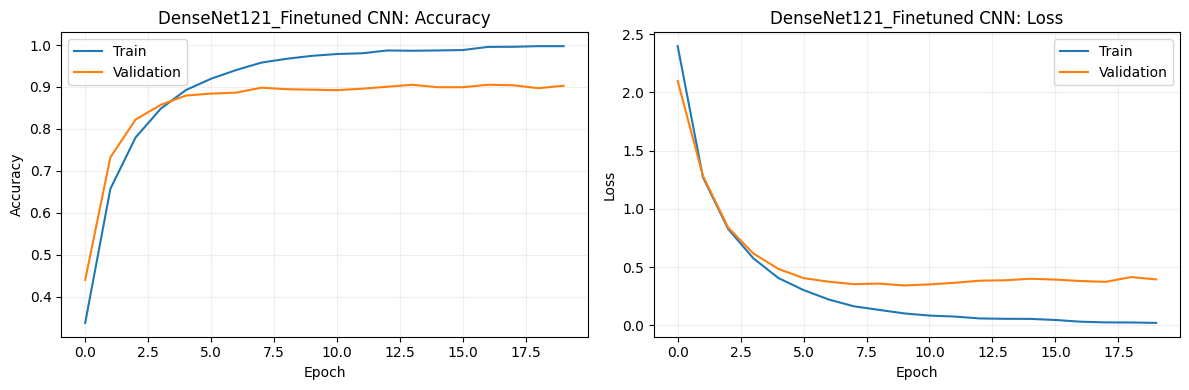

Best epoch: 10
Train acc: 0.9743 | Val acc: 0.8936
Train loss: 0.1028 | Val loss: 0.3427


In [12]:
#Training and validation accurcay and loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set(title="DenseNet121_Finetuned CNN: Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.2)

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set(title="DenseNet121_Finetuned CNN: Loss", xlabel="Epoch", ylabel="Loss")
axes[1].legend(); axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig("DenseNet121_Finetuned_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

best = int(np.argmin(history.history["val_loss"]))
print(f"Best epoch: {best + 1}")
print(f"Train acc: {history.history['accuracy'][best]:.4f} | Val acc: {history.history['val_accuracy'][best]:.4f}")
print(f"Train loss: {history.history['loss'][best]:.4f} | Val loss: {history.history['val_loss'][best]:.4f}")

In [13]:
#final evaluation and classification report (test set, run once)
print("DenseNet121_Finetuned")
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}\n")

y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

DenseNet121_Finetuned
Test loss: 0.4621 | Test accuracy: 0.8889

              precision    recall  f1-score   support

           A      0.913     0.656     0.764        32
           B      0.886     0.939     0.912        33
           C      0.889     0.941     0.914        34
           D      0.886     0.939     0.912        33
           E      0.857     0.938     0.896        32
           F      1.000     0.941     0.970        34
           G      0.741     0.667     0.702        30
           H      0.842     0.970     0.901        33
           I      0.793     0.697     0.742        33
           J      1.000     0.941     0.970        34
           K      0.938     0.909     0.923        33
           L      0.722     0.765     0.743        34
           M      1.000     0.903     0.949        31
           N      0.800     0.933     0.862        30
           O      0.944     1.000     0.971        34
           P      0.969     0.969     0.969        32
           Q    

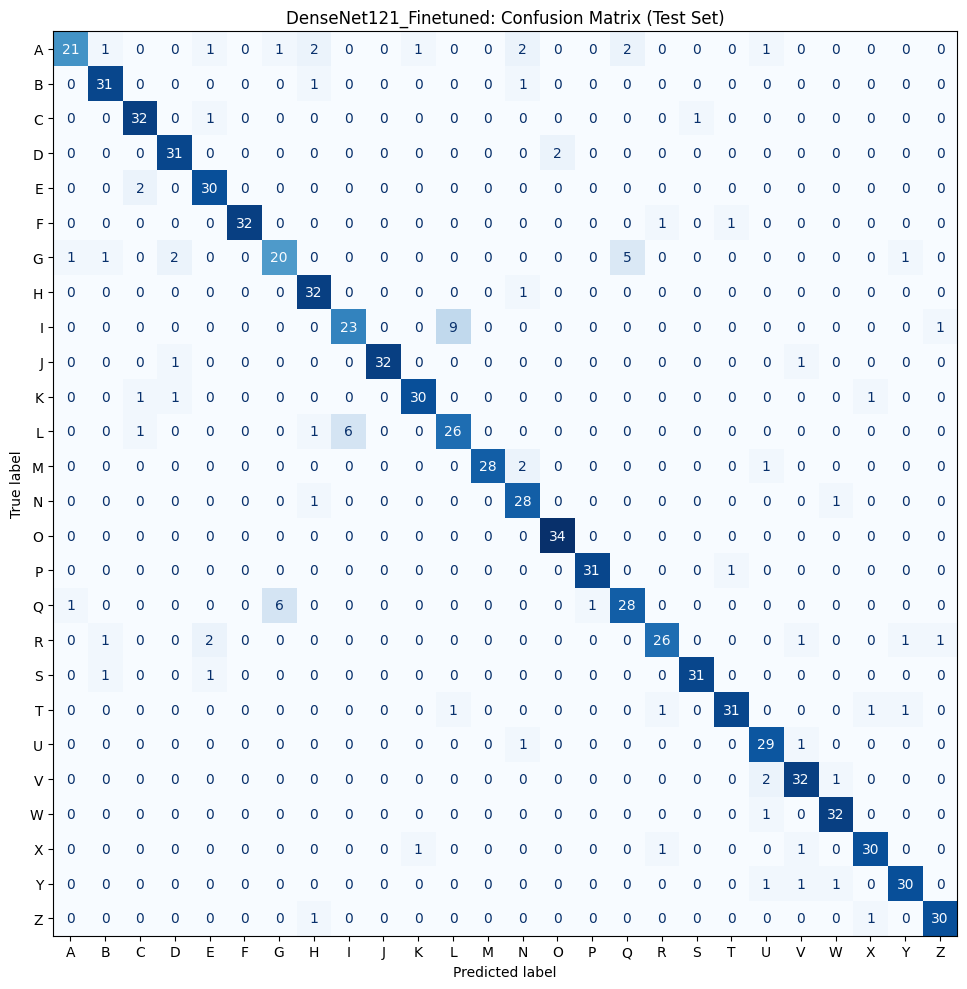

Most confused (true -> predicted):
  I -> L: 9
  L -> I: 6
  Q -> G: 6
  G -> Q: 5
  A -> H: 2
  A -> N: 2
  A -> Q: 2
  D -> O: 2
  E -> C: 2
  G -> D: 2


In [14]:
#Confusion matrix and most-confused pairs
cm = confusion_matrix(y_test, y_pred, labels=range(26))

fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("DenseNet121_Finetuned: Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("DenseNet121_Finetuned_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# Top confused pairs (true -> predicted)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], off[i, j])
         for i in range(26) for j in range(26) if off[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Most confused (true -> predicted):")
for t, p, n in pairs[:10]:
    print(f"  {t} -> {p}: {n}")

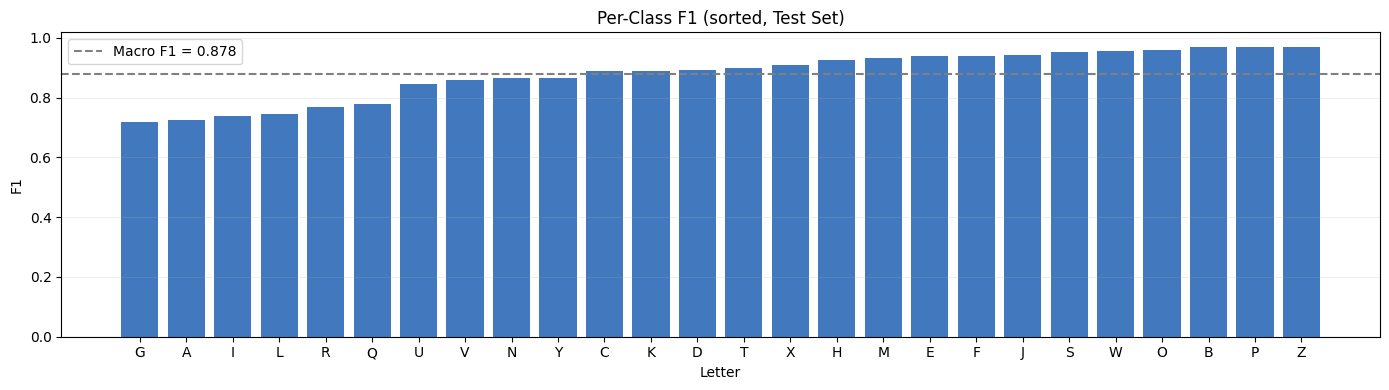

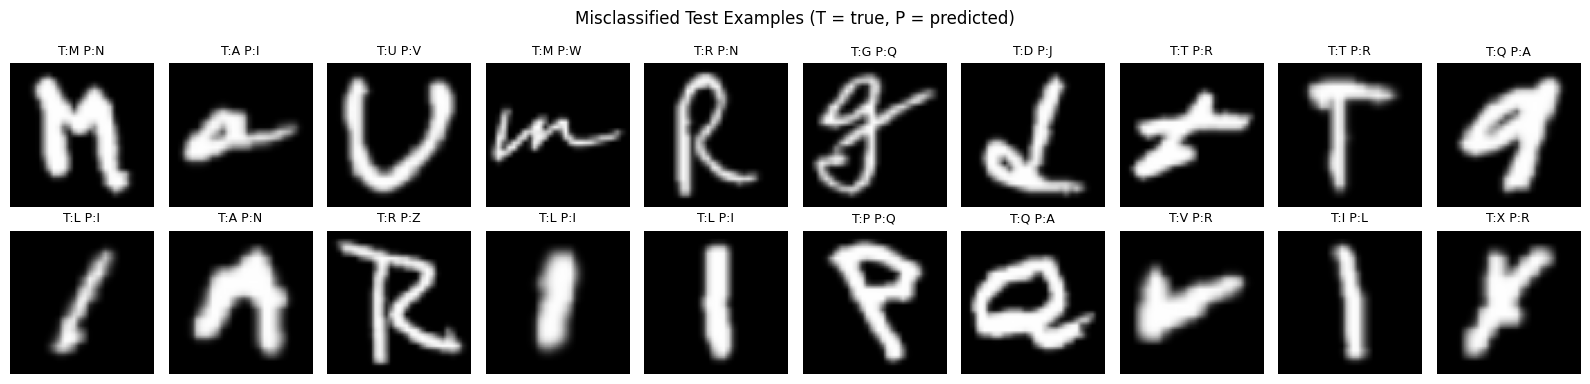

In [ ]:
#Per-class F1 and misclassified examples
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred, average=None, labels=range(26))
order = np.argsort(f1)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar([CLASS_NAMES[i] for i in order], f1[order], color="#4178BE")
ax.axhline(f1.mean(), color="gray", linestyle="--", label=f"Macro F1 = {f1.mean():.3f}")
ax.set(title="Per-Class F1 (sorted, Test Set)", xlabel="Letter", ylabel="F1")
ax.legend(); ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig("baseline_per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()

# Misclassified examples
wrong = np.where(y_pred != y_test)[0]
rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(20, len(wrong)), replace=False)

fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"T:{CLASS_NAMES[y_test[i]]} P:{CLASS_NAMES[y_pred[i]]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified Test Examples (T = true, P = predicted)")
plt.tight_layout()
plt.savefig("densenet201_misclassified.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
#save model and results
model.save("DenseNet121_Finetuned.keras")
print("Saved DenseNet121_Finetuned.keras")

Saved DenseNet121_Finetuned.keras


# Testing with raw data

In [15]:
!pip install nltk

In [16]:

import nltk
nltk.download('words')
from nltk.corpus import words
word_list = words.words()


[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.


In [524]:
import random as rand
import string

# 1. Pre-filter word_list for clean 5-letter lowercase words (a-z only, no punctuation)
alphabet = set(string.ascii_lowercase)
valid_words = [
    w for w in word_list
    if len(w) == 5 and w.islower() and set(w).issubset(alphabet)
]

# 2. Greedily pick 9 random words that cover all 26 letters
while True:
    generated_words = []
    uncovered = set(alphabet)
    pool = valid_words.copy()
    rand.shuffle(pool)  # Keeps every run completely random

    for _ in range(9):
        if uncovered:
            # Find the maximum number of missing letters any word in the pool can cover
            best_gain = max(len(set(w) & uncovered) for w in pool)
            # Randomly pick among all words tied for that highest coverage gain
            candidates = [w for w in pool if len(set(w) & uncovered) == best_gain]
            chosen = rand.choice(candidates)
        else:
            # Once all 26 letters are covered, pick completely at random
            chosen = rand.choice(pool)

        generated_words.append(chosen)
        uncovered -= set(chosen)
        pool.remove(chosen)

    # Confirm all 26 letters were covered within the 9 words
    if not uncovered:
        break

# Shuffle final 9 words so rare-letter words aren't always in the first row
rand.shuffle(generated_words)

# 3. Print 3x3 grid and save uppercase ground_truth.txt
print("========Randomly Generated Pangram Grid (26/26 Letters)========")
for i in range(3):
    print("\n")
    for j in range(3):
        word = generated_words[i * 3 + j]
        print(f"{word:<10}", end="")
print("\n")


========Randomly Generated Pangram Grid (26/26 Letters)========


fresh     punky     squin     

corgi     djave     claim     

least     zambo     dewax     



## After you have chosen your words, write them down on a piece of printer paper. Then, upload them here.

### For example, take a picture and then title the file, `handwriting_scan.jpg`. Then upload the photo.

In [525]:
from google.colab import files
uploaded = files.upload()

Saving Grid_3.jpg to Grid_3.jpg


### Give your image a global name, e.g. `handwriting_scan.jpg`

In [526]:
img_name = "Grid_3.jpg"
with open(f"{img_name}.txt", "w", encoding="utf-8") as f:
    for word in generated_words:
        f.write(word.upper() + "\n")

## The segmentation code will automatically extract the letters that you have written.

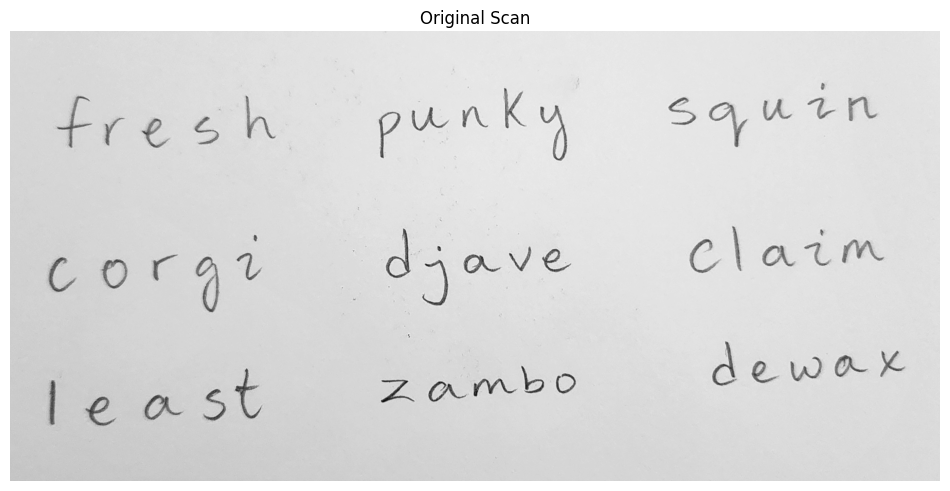

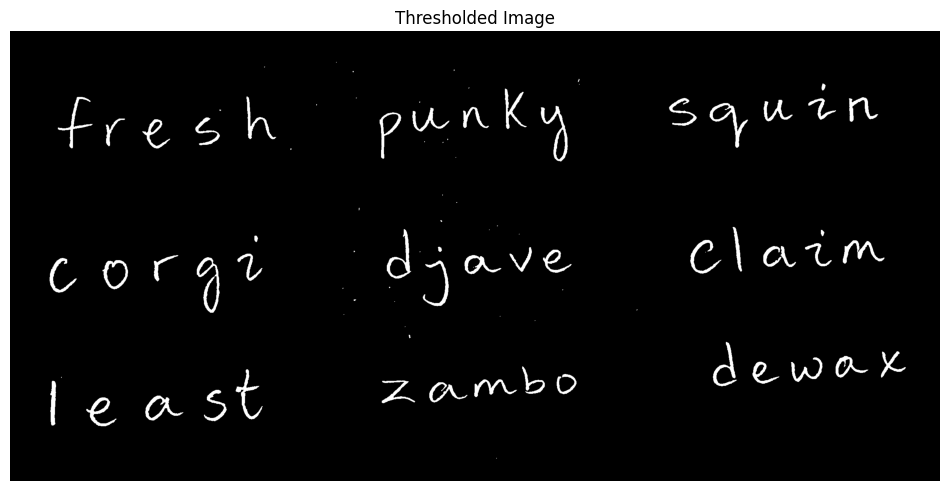

Filtered boxes: 45


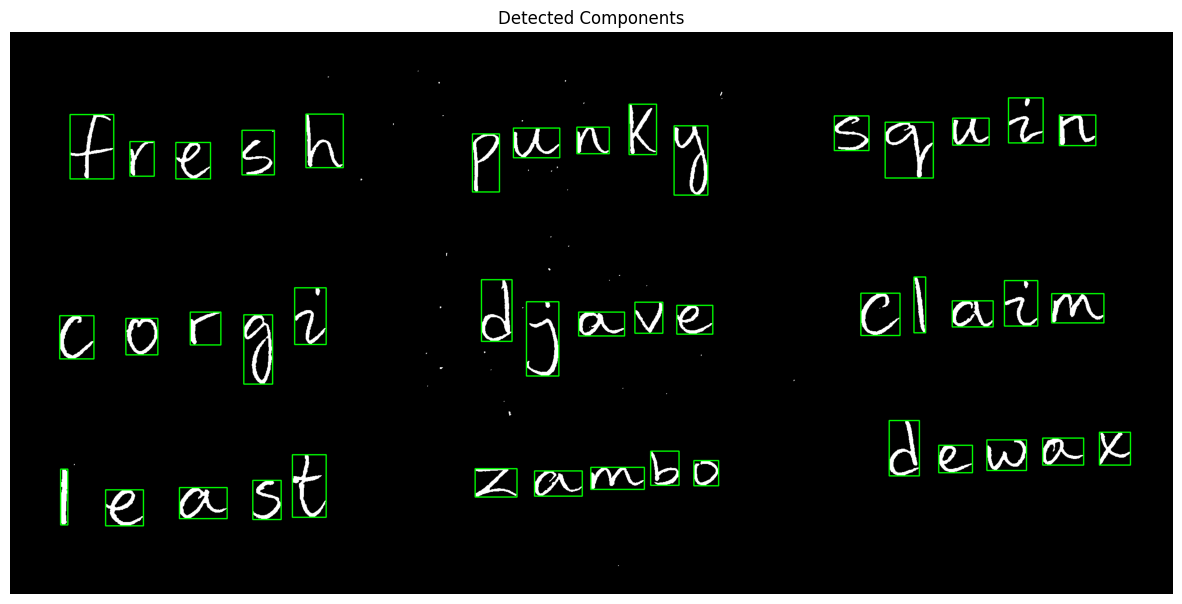

Row at y≈248: found 15 characters
Row at y≈643: found 15 characters
Row at y≈986: found 15 characters
Extracted 45 characters


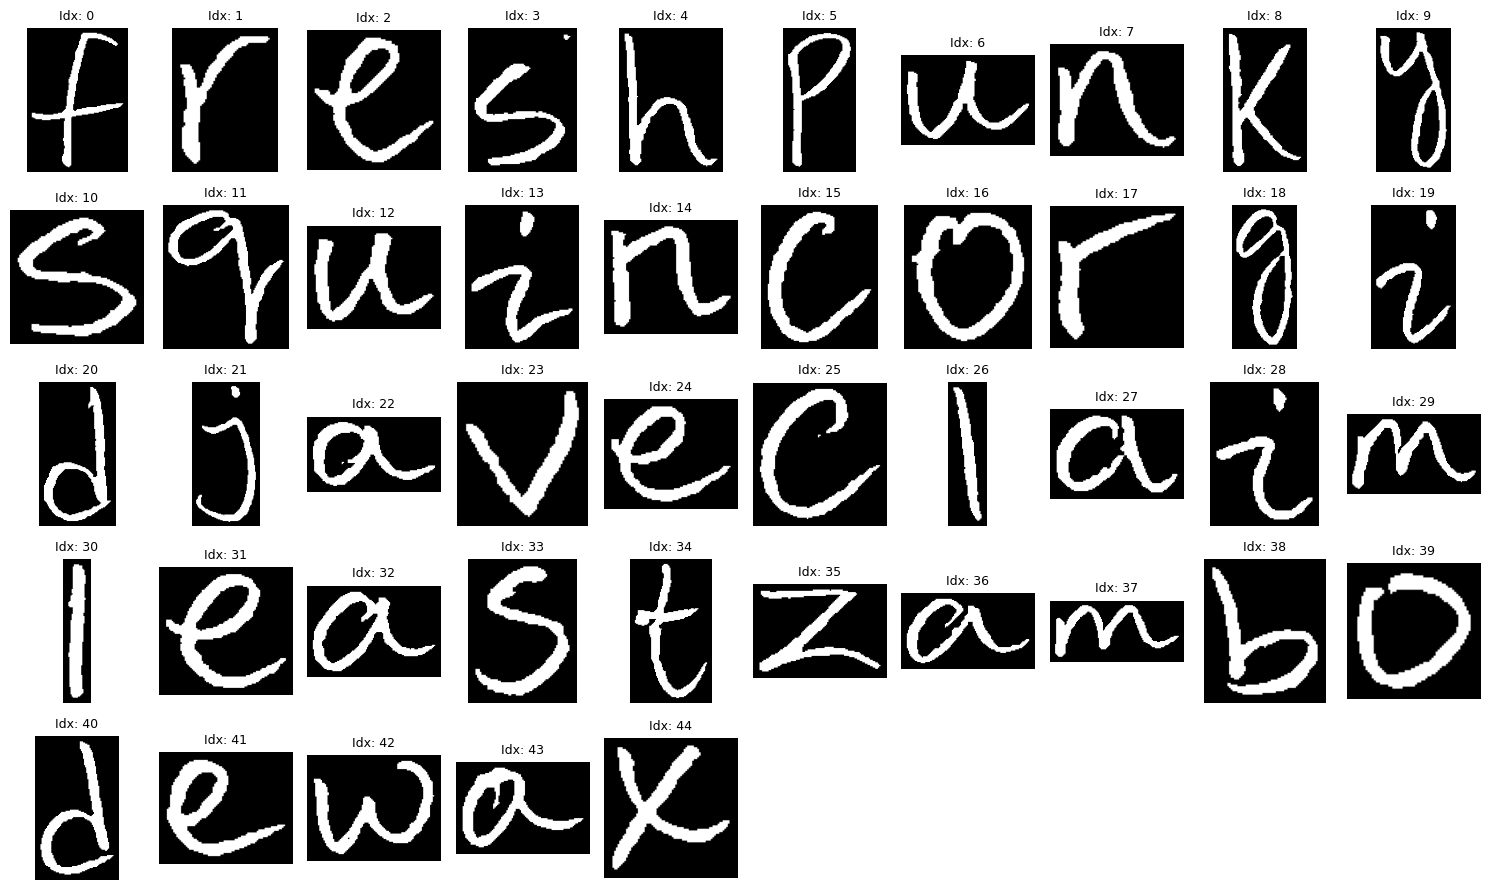

In [527]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

# ============================================================
# Load image
# ============================================================

img = cv2.imread(
    img_name,
    cv2.IMREAD_GRAYSCALE
)

# ============================================================
# Remove scanner border
# ============================================================

#img = img[:, 40:]

# ============================================================
# Show original
# ============================================================

plt.figure(figsize=(12, 12))
plt.imshow(img, cmap="gray")
plt.title("Original Scan")
plt.axis("off")
plt.show()

# ============================================================
# Illumination correction
# ============================================================

background = cv2.GaussianBlur(
    img,
    (0, 0),
    sigmaX=75,
    sigmaY=75
)

normalized = cv2.divide(
    img,
    background,
    scale=255
)

# ============================================================
# Adaptive threshold
# ============================================================
denoised = cv2.bilateralFilter(
    normalized,
    d=5,
    sigmaColor=50,
    sigmaSpace=50
)

thresh = cv2.adaptiveThreshold(
    denoised,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    51,
    15
)

# ============================================================
# Strengthen handwriting
# ============================================================

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (2, 2)
)


thresh = cv2.morphologyEx(
    thresh,
    cv2.MORPH_CLOSE,
    kernel
)

thresh = cv2.morphologyEx(
    thresh,
    cv2.MORPH_OPEN,
    kernel
)

# ============================================================
# Show thresholded image
# ============================================================

plt.figure(figsize=(12, 12))
plt.imshow(thresh, cmap="gray")
plt.title("Thresholded Image")
plt.axis("off")
plt.savefig(f"{img_name}_Thresholded_Image.png", dpi=200, bbox_inches="tight")
plt.show()

# ============================================================
# Connected components
# ============================================================

num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        thresh,
        connectivity=8
    )
)

# ============================================================
# Component filtering
# ============================================================

raw_comps = []
for i in range(1, num_labels):
    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    area = stats[i, cv2.CC_STAT_AREA]

    if area < 12 or w > img.shape[1] * 0.25 or h > img.shape[0] * 0.25:
        continue
    raw_comps.append((x, y, w, h, area))

tall_heights = [h for (_, _, _, h, area) in raw_comps if area >= 50]
median_h = np.median(tall_heights) if tall_heights else 60.0

letter_boxes = []
dot_boxes = []

for (x, y, w, h, area) in raw_comps:
    if h < median_h * 0.40 and w < median_h * 0.45 and area >= 12:
        dot_boxes.append((x, y, w, h))
        continue

    if h < median_h * 0.35 or w < 4:
        continue

    component = thresh[y:y+h, x:x+w]
    if np.count_nonzero(component) / (w * h) < 0.08:
        continue

    letter_boxes.append((x, y, w, h))

final_boxes = []
for (lx, ly, lw, lh) in letter_boxes:
    left, top, right, bottom = lx, ly, lx + lw, ly + lh

    for (dx, dy, dw, dh) in dot_boxes:
        dot_cx = dx + dw / 2
        dot_bottom = dy + dh

        horiz_ok = (lx - median_h * 0.25) <= dot_cx <= (lx + lw + median_h * 0.25)
        vert_ok = -median_h * 0.10 <= (ly - dot_bottom) <= median_h * 0.80

        if horiz_ok and vert_ok:
            left = min(left, dx)
            top = min(top, dy)
            right = max(right, dx + dw)
            bottom = max(bottom, dy + dh)

    final_boxes.append((left, top, right - left, bottom - top))

boxes = final_boxes
boxes = sorted(boxes, key=lambda b: b[0])
stitched = []

for box in boxes:
    if not stitched:
        stitched.append(box)
        continue

    px, py, pw, ph = stitched[-1]
    cx, cy, cw, ch = box

    # Check if they are on the same row vertically AND overlap/nearly touch horizontally
    same_row = abs((py + ph / 2) - (cy + ch / 2)) < median_h * 0.8
    horiz_gap = cx - (px + pw)  # Negative means boxes overlap horizontally!

    if same_row and horiz_gap <= 2:
        nx = min(px, cx)
        ny = min(py, cy)
        nw = max(px + pw, cx + cw) - nx
        nh = max(py + ph, cy + ch) - ny
        stitched[-1] = (nx, ny, nw, nh)
    else:
        stitched.append(box)

boxes = stitched
print(f"Filtered boxes: {len(boxes)}")

# ============================================================
# Draw accepted components
# ============================================================

preview = cv2.cvtColor(
    thresh,
    cv2.COLOR_GRAY2BGR
)

for i, (x, y, w, h) in enumerate(boxes):

    cv2.rectangle(
        preview,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(15, 10))
plt.imshow(preview)
plt.title("Detected Components")
plt.axis("off")
plt.savefig(f"{img_name}_Detected_Components.png", dpi=200, bbox_inches="tight")
plt.show()

# ============================================================
# Sort by row then column
# ============================================================

ROW_TOL = 90

boxes = sorted(
    boxes,
    key=lambda b: (b[1] + b[3] / 2, b[0])
)

rows = []
for box in boxes:
    x, y, w, h = box
    cy = y + h / 2
    placed = False

    for row in rows:
        if abs(cy - row["cy"]) < ROW_TOL:
            row["boxes"].append(box)
            # Update running average center for slightly tilted lines
            row["cy"] = np.mean([b[1] + b[3] / 2 for b in row["boxes"]])
            placed = True
            break

    if not placed:
        rows.append({"cy": cy, "boxes": [box]})
# ============================================================
# Extract characters
# ============================================================

characters = []
for row in sorted(rows, key=lambda r: r["cy"]):
    row["boxes"] = sorted(row["boxes"], key=lambda b: b[0])
    print(f"Row at y≈{int(row['cy'])}: found {len(row['boxes'])} characters")  # Should print 15 per row!
    for (x, y, w, h) in row["boxes"]:
        padding = 5
        x0, y0 = max(x - padding, 0), max(y - padding, 0)
        x1, y1 = min(x + w + padding, thresh.shape[1]), min(y + h + padding, thresh.shape[0])
        characters.append(thresh[y0:y1, x0:x1])

print(
    f"Extracted {len(characters)} characters"
)

# ============================================================
# Visualize extracted chars
# ============================================================

def plot_imageGrid(characters, cols=5):
  cols = 10
  rows = math.ceil(len(characters) / cols)
  fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.8), squeeze=False)

  for i, ax in enumerate(axes.flat):
      if i < len(characters):
          ax.imshow(characters[i].squeeze(), cmap="gray")
          ax.set_title(f"Idx: {i}", fontsize=9)
      ax.axis("off")

  plt.tight_layout()
  plt.show()

plot_imageGrid(characters, cols=5)

### Note, if you see a number greater than the (3x3x5) word matrix, try again with another paper and space out the letters.

### Transform letters into EMNIST format

In [528]:
import numpy as np
import tensorflow as tf

def preprocess_character(char_img, input_shape, pad_ratio=0.10, preprocess_fn=None):
    """
    Preprocesses cropped handwriting for a 3-channel transfer-learning CNN.

    Args:
        char_img: 2D grayscale array (H, W).
        input_shape: Target (height, width) expected by your pretrained model (e.g., (32, 32) or (96, 96)).
        pad_ratio: Border padding ratio (~0.10 matches EMNIST framing).
        preprocess_fn: Optional Keras preprocess_input function (e.g., tf.keras.applications.mobilenet_v2.preprocess_input).
                       Leave None if your model already has a preprocessing/rescaling layer inside it.
    """
    img = np.array(char_img, dtype=np.float32)

    if img.max() > 1.0:
        img /= 255.0

    # 1. Thicken thin pen strokes and smooth binary edges to match EMNIST/dataset style
    k_size = max(2, int(min(img.shape[:2]) * 0.06))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
    img = cv2.dilate(img, kernel, iterations=1)
    img = cv2.GaussianBlur(img, (13, 13), 0)

    # 2. Pad into a square with ~10% border margin
    h, w = img.shape[:2]
    max_side = max(h, w)
    pad_margin = int(max_side * pad_ratio)
    square_size = max_side + 2 * pad_margin

    square_img = np.zeros((square_size, square_size), dtype=np.float32)
    y_offset = (square_size - h) // 2
    x_offset = (square_size - w) // 2
    square_img[y_offset:y_offset + h, x_offset:x_offset + w] = img

    # 3. Resize to target spatial shape and expand to 3 RGB channels: (H, W, 3)
    tensor_img = square_img[..., np.newaxis]
    tensor_img = tf.image.resize(tensor_img, input_shape, method="area")
    tensor_img = tf.image.grayscale_to_rgb(tensor_img).numpy().astype(np.float32)

    # 4. Normalize peak ink brightness to [0.0, 1.0] (matches colleague's .npz range)
    if tensor_img.max() > 0:
        tensor_img /= tensor_img.max()

    # 5. Apply backbone-specific scaling if not already embedded inside the model
    if preprocess_fn is not None:
        tensor_img = preprocess_fn(tensor_img * 255.0)

    return tensor_img

In [529]:
X_handwriting = np.array([
    preprocess_character(char, (64,64), pad_ratio=0.10, preprocess_fn=None)
    for char in characters
])
print(X_handwriting.shape)

(45, 64, 64, 3)


## Generate the labels automatically

In [530]:
CLASS_NAMES = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
label_map = {c: i for i, c in enumerate(CLASS_NAMES)}

letters = []
with open(f"{img_name}.txt", "r", encoding="utf-8") as f:
    for line_num, line in enumerate(f, start=1):
        # Keep ONLY valid A-Z uppercase letters (ignores spaces, newlines, punctuation)
        valid_chars = [c for c in line.upper() if c in label_map]
        letters.extend(valid_chars)
        print(f"Line {line_num}: '{line.strip()}' -> {len(valid_chars)} letters")

y_handwriting = np.array([label_map[c] for c in letters])

print("\n--- Summary ---")
print("Extracted letters:", "".join(letters))
print("X_handwriting shape:", X_handwriting.shape)
print("y_handwriting shape:", y_handwriting.shape)

Line 1: 'FRESH' -> 5 letters
Line 2: 'PUNKY' -> 5 letters
Line 3: 'SQUIN' -> 5 letters
Line 4: 'CORGI' -> 5 letters
Line 5: 'DJAVE' -> 5 letters
Line 6: 'CLAIM' -> 5 letters
Line 7: 'LEAST' -> 5 letters
Line 8: 'ZAMBO' -> 5 letters
Line 9: 'DEWAX' -> 5 letters

--- Summary ---
Extracted letters: FRESHPUNKYSQUINCORGIDJAVECLAIMLEASTZAMBODEWAX
X_handwriting shape: (45, 64, 64, 3)
y_handwriting shape: (45,)


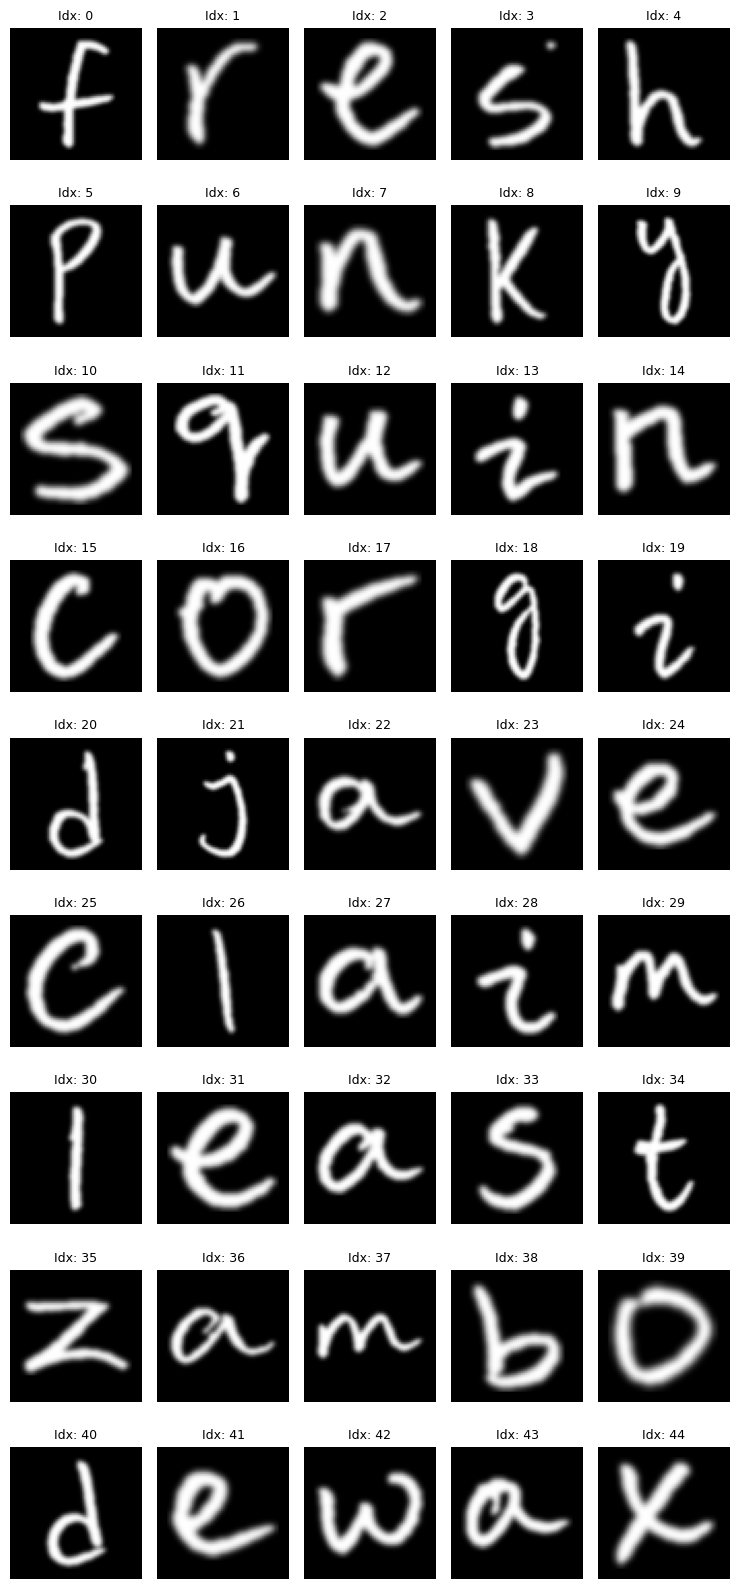

In [539]:
def plot_imageGrid(characters, cols=5):
  rows = math.ceil(len(characters) / cols)
  fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.8), squeeze=False)

  for i, ax in enumerate(axes.flat):
      if i < len(characters):
          ax.imshow(characters[i].squeeze(), cmap="gray")
          ax.set_title(f"Idx: {i}", fontsize=9)
      ax.axis("off")

  plt.tight_layout()

  plt.show()

plot_imageGrid(X_handwriting, cols=5)

## Evaluating with model

In [532]:
test_loss, test_acc = model.evaluate(
    X_handwriting,
    y_handwriting,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.5612
Test accuracy: 0.8667


In [533]:
y_pred_classes = np.argmax(model.predict(X_handwriting), axis=1)

# Print true vs predicted side-by-side for the first 15 letters (first row: matra senso camel)
true_str = "".join(CLASS_NAMES[i] for i in y_handwriting[:15])
pred_str = "".join(CLASS_NAMES[i] if i < 26 else "?" for i in y_pred_classes[:15])

print("True:     ", true_str)
print("Predicted:", pred_str)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 206ms/step
True:      FRESHPUNKYSQUIN
Predicted: FREJHPUNKBSQUZN


In [534]:
y_prob = model.predict(
    X_handwriting,
    verbose=0
)

y_pred = y_prob.argmax(axis=1)

In [535]:
from sklearn.metrics import classification_report

#y_pred_classes = np.argmax(y_pred, axis=1)
print("------------RAW DATA CLASSIFICATION REPORT | DENSENET_121------")
print(
    classification_report(
        y_handwriting,
        y_pred,
        labels=range(len(CLASS_NAMES)), # Ensures all 26 letters are accounted for
        target_names=CLASS_NAMES,       # Maps 0-25 to 'A'-'Z'
        digits=3,
        zero_division=0                 # Prevents warnings for letters not in your 60-letter sample
    )
)

------------RAW DATA CLASSIFICATION REPORT | DENSENET_121------
              precision    recall  f1-score   support

           A      1.000     1.000     1.000         5
           B      0.500     1.000     0.667         1
           C      1.000     1.000     1.000         2
           D      1.000     1.000     1.000         2
           E      1.000     1.000     1.000         4
           F      1.000     1.000     1.000         1
           G      1.000     1.000     1.000         1
           H      1.000     1.000     1.000         1
           I      0.000     0.000     0.000         3
           J      0.250     1.000     0.400         1
           K      1.000     1.000     1.000         1
           L      1.000     1.000     1.000         2
           M      1.000     1.000     1.000         2
           N      1.000     1.000     1.000         2
           O      1.000     1.000     1.000         2
           P      1.000     1.000     1.000         1
           Q     

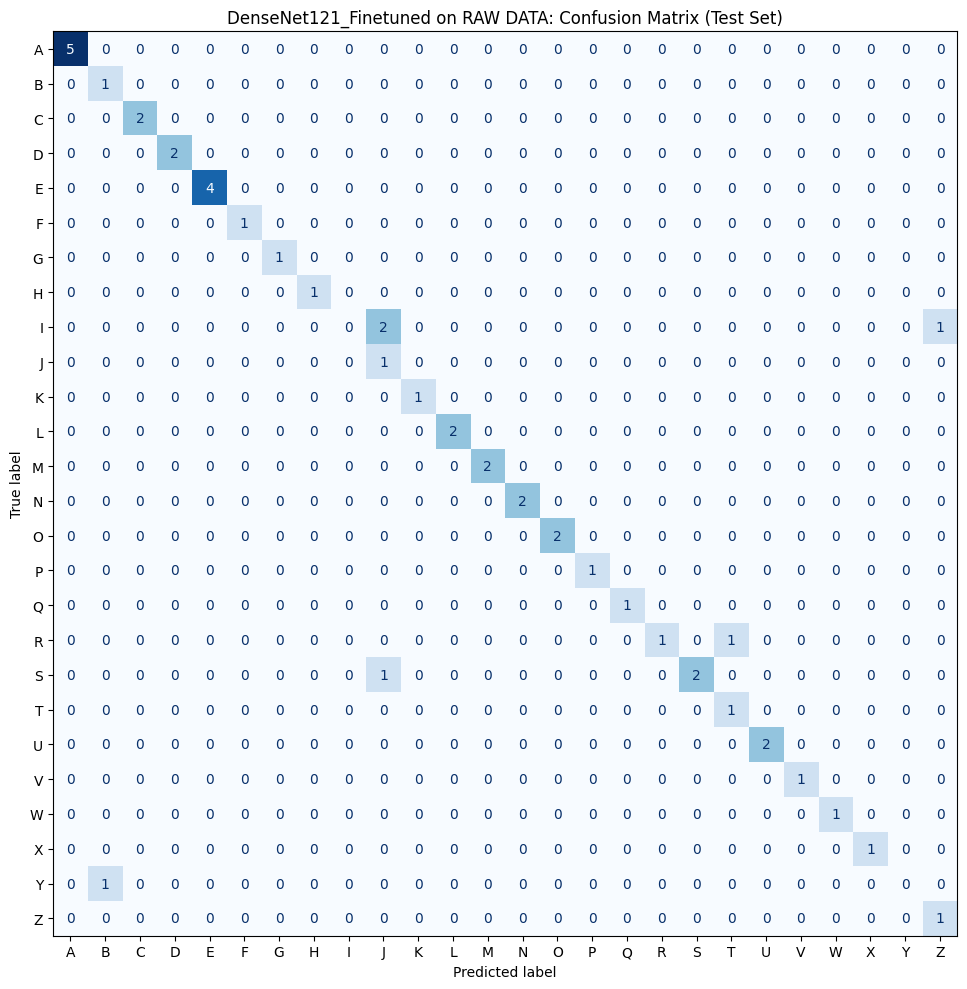

In [536]:
#Confusion matrix and most-confused pairs
cm = confusion_matrix(y_handwriting, y_pred, labels=range(26))

fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("DenseNet121_Finetuned on RAW DATA: Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig(f"{img_name}_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

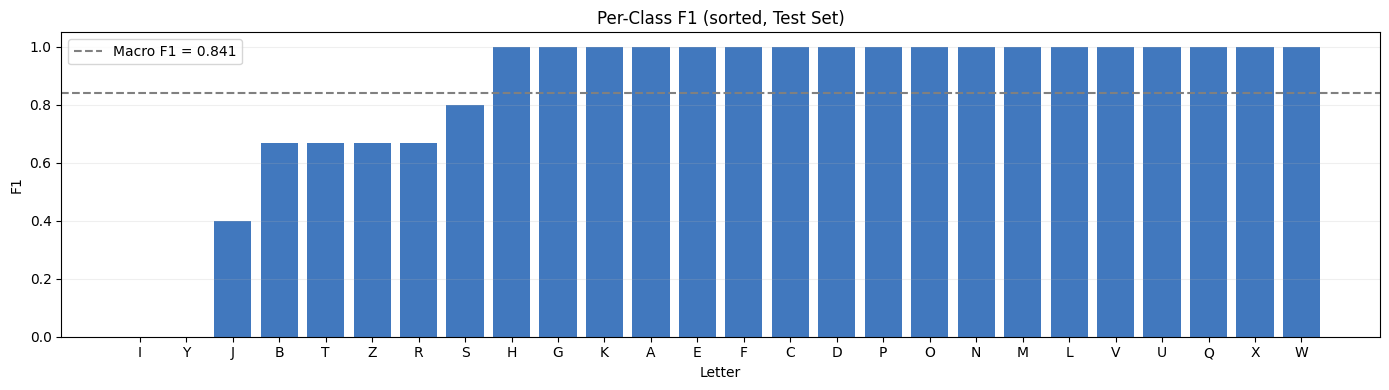

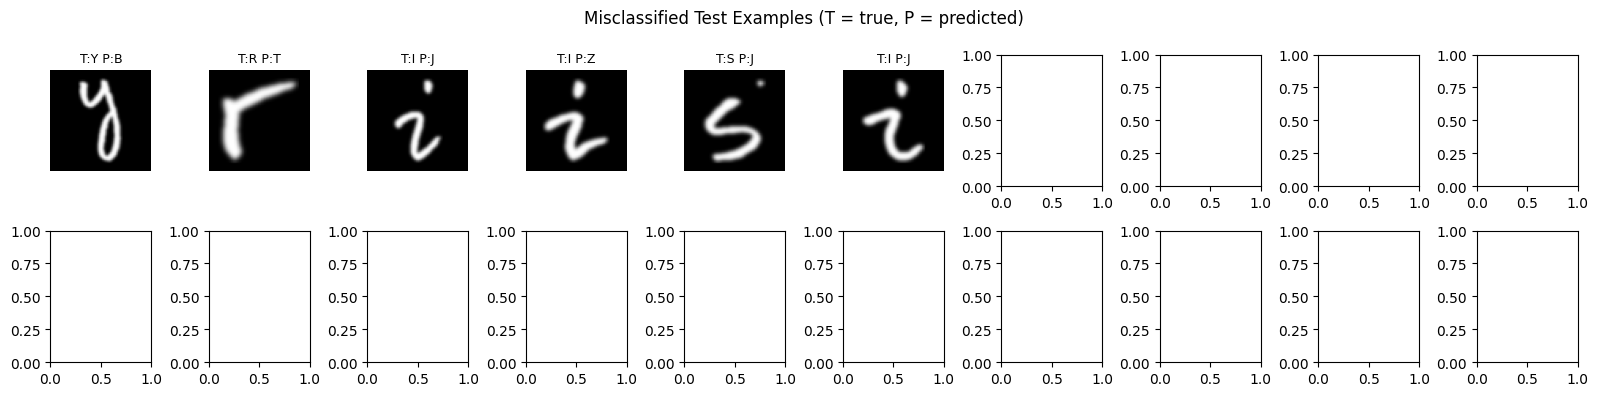

In [537]:
#Per-class F1 and misclassified examples
from sklearn.metrics import f1_score

f1 = f1_score(y_handwriting, y_pred, average=None, labels=range(26))
order = np.argsort(f1)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar([CLASS_NAMES[i] for i in order], f1[order], color="#4178BE")
ax.axhline(f1.mean(), color="gray", linestyle="--", label=f"Macro F1 = {f1.mean():.3f}")
ax.set(title="Per-Class F1 (sorted, Test Set)", xlabel="Letter", ylabel="F1")
ax.legend(); ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{img_name}_per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()

# Misclassified examples
wrong = np.where(y_pred != y_handwriting)[0]
rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(20, len(wrong)), replace=False)

fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_handwriting[i].squeeze(), cmap="gray")
    ax.set_title(f"T:{CLASS_NAMES[y_handwriting[i]]} P:{CLASS_NAMES[y_pred[i]]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified Test Examples (T = true, P = predicted)")
plt.tight_layout()
plt.savefig(f"{img_name}_misclassified.png", dpi=200, bbox_inches="tight")
plt.show()

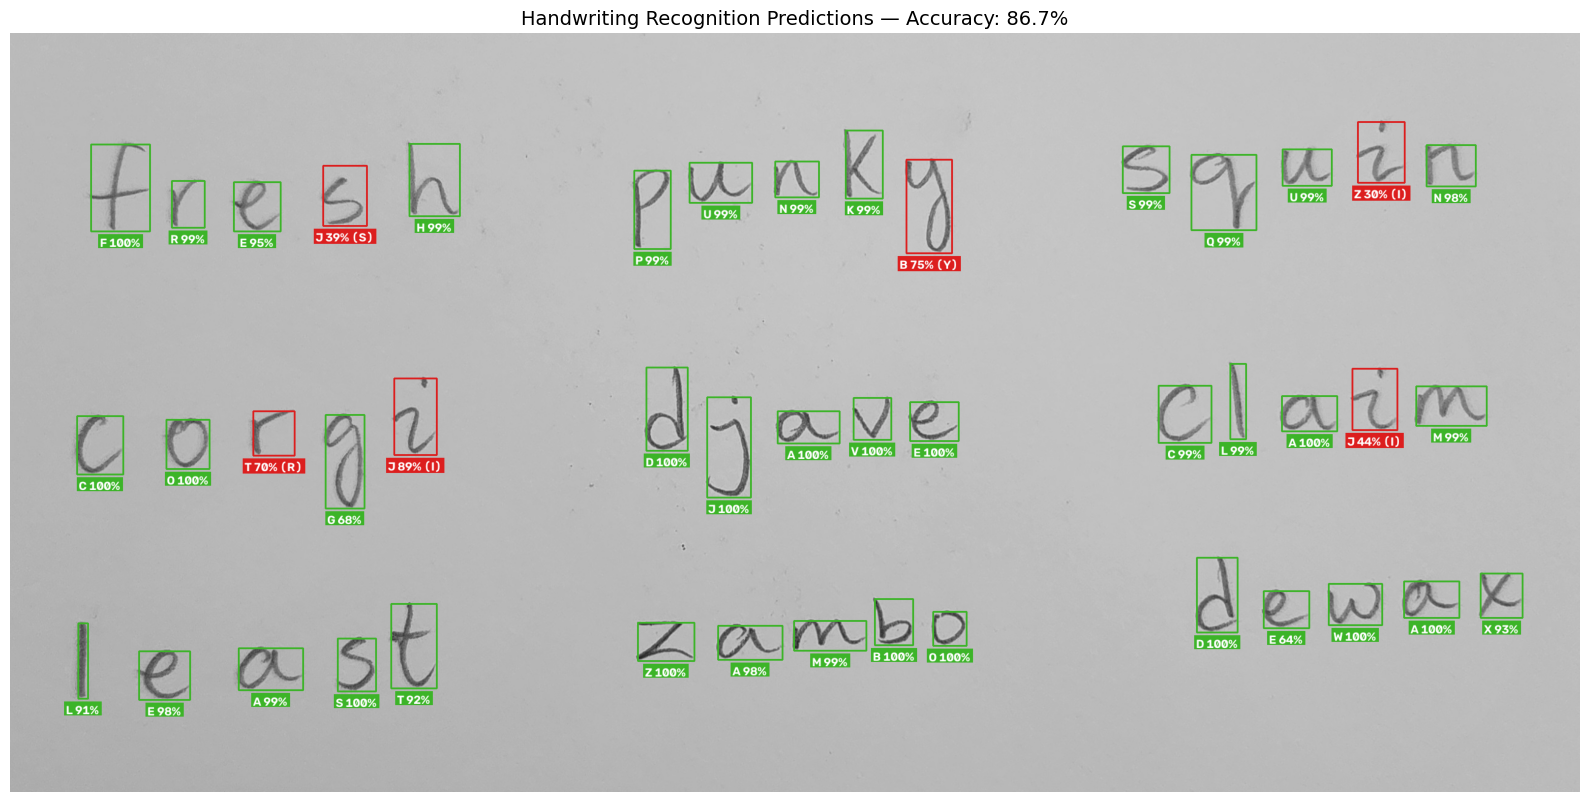

In [538]:
# 1. Start with a clean BGR copy of your original grayscale scan so text is crisp
annotated = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# 2. Flatten your sorted row boxes in the exact same order as `characters`
sorted_boxes = [
    box
    for row in sorted(rows, key=lambda r: r["cy"])
    for box in row["boxes"]
]

# 3. Get predicted classes and max probabilities
y_pred_probs = model.predict(X_handwriting, verbose=0)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_pred_conf = np.max(y_pred_probs, axis=1)

# 4. Draw each bounding box and footer probability label
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.65
thickness = 2

for i, (x, y, w, h) in enumerate(sorted_boxes):
    pred_idx = y_pred_classes[i]
    true_idx = y_handwriting[i]
    conf = y_pred_conf[i] * 100

    pred_letter = CLASS_NAMES[pred_idx]
    is_correct = (pred_idx == true_idx)

    # BGR colors: Emerald Green for correct, Crimson Red for incorrect
    color = (40, 180, 60) if is_correct else (30, 30, 220)

    # Draw bounding box
    cv2.rectangle(annotated, (x, y), (x + w, y + h), color, 2)

    # Format footer string (e.g., "M 99%" or "D 64% (A)" if missed)
    label_text = f"{pred_letter} {conf:.0f}%" if is_correct else f"{pred_letter} {conf:.0f}% ({CLASS_NAMES[true_idx]})"

    # Measure text size to draw a solid background pill for readability
    (text_w, text_h), baseline = cv2.getTextSize(label_text, font, font_scale, thickness)
    text_x = max(0, x + (w - text_w) // 2)  # Center text horizontally under the box
    text_y = min(annotated.shape[0] - 5, y + h + text_h + 8)

    # Solid colored footer badge + crisp white text
    cv2.rectangle(
        annotated,
        (text_x - 3, text_y - text_h - 3),
        (text_x + text_w + 3, text_y + baseline),
        color,
        -1
    )
    cv2.putText(
        annotated,
        label_text,
        (text_x, text_y),
        font,
        font_scale,
        (255, 255, 255),
        thickness,
        cv2.LINE_AA
    )

# 5. Display with Matplotlib (convert BGR -> RGB)
plt.figure(figsize=(16, 12))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Handwriting Recognition Predictions — Accuracy: {np.mean(y_pred_classes == y_handwriting):.1%}", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.savefig(f"{img_name}_Handwriting_Recognition_Predictions.png", dpi=200, bbox_inches="tight")
plt.show()
